# Can AI Predict Tomorrow?

## Will 2 pm tomorrow in Accra be as hot as today?

![A line of temperature history running into a shaded forecast band](https://raw.githubusercontent.com/RichelCode/Youtube/main/forecasting-made-easy/01-can-ai-predict-tomorrow/figures/fig_title.png)

Every forecast answers two questions: **what happens next**, and **how sure are we?**
Today we test an AI model on both.

**Forecasting Made Easy, Episode 1** · Richel Attafuah, GStat

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/RichelCode/Youtube/blob/main/forecasting-made-easy/01-can-ai-predict-tomorrow/can_ai_predict_tomorrow.ipynb)

# What you will learn today

1. What forecasting really is (you already do it)
2. What a **time series** is, and its three ingredients
3. The two golden rules: **never shuffle time**, and **ranges beat single numbers**
4. The **lazy forecast** every model must beat
5. How an **AI foundation model** like Chronos-2 reads numbers
6. A fair race on 56 days of real data, in Python
7. **Three checks** before you trust any AI forecast

No maths background needed. If you can read a chart, you can follow this.

# You already forecast

| Everyday question | What you look at | Your forecast |
|---|---|---|
| How long will my commute take at 5 pm on Friday? | Past Fridays | "Traffic will be bad, leave early" |
| Will the lights go off tonight? | The power cuts of the past few weeks | "Charge my phone now" |
| How much food will the family finish on Sunday? | Past Sundays | "Cook a little more than usual" |

**In plain words:** you use patterns from the past to make a decision about an uncertain future.
**That is forecasting.** Today we do it with a bit more discipline, and with data.

# What is a time series?

| Time | Temperature (°C) |
|---|---|
| 12:00 | 31.8 |
| 13:00 | 32.4 |
| 14:00 | 32.1 |
| 15:00 | 31.3 |

- A list of values, each with a **timestamp**, kept **in order**
- Examples: hourly temperature, daily mobile-money transactions, monthly exchange rates, daily sales at a shop

**In plain words:** a time series is like a diary. Shuffle the pages and every word is still there,
but the story is gone. **The order is where the information lives.**

*(The numbers in the table are an illustration.)*

# The three ingredients: trend, seasonality, noise

![Accra temperature split into a slow trend, a repeating daily rhythm, and noise](https://raw.githubusercontent.com/RichelCode/Youtube/main/forecasting-made-easy/01-can-ai-predict-tomorrow/figures/fig_decomp.png)

- **Trend** (top): the slow drift over weeks, like a child growing taller
- **Seasonality** (middle): the rhythm that repeats on a fixed cycle. Here: every 24 hours, cool at dawn, hot in the afternoon
- **Noise** (bottom): what is left over, the surprises nobody can predict

**Watch the sharp dip around 21 October.** That unusual day comes back later in the race.

# Golden rule 1: never shuffle time

![Correct split: all test days after training days. Leaky split: test days mixed in](https://raw.githubusercontent.com/RichelCode/Youtube/main/forecasting-made-easy/01-can-ai-predict-tomorrow/figures/fig_split.png)

- **Top (correct):** learn from the past, test on the future
- **Bottom (wrong):** test days are mixed in with training days, so the model learns from days that come *after* the ones it is tested on

**In plain words:** it is like studying for an exam with next week's answers mixed into your notes.
You score well, but it is not real. This mistake is called **data leakage**.

# Golden rule 2: ranges beat single numbers

![Two days of history, then a forecast line inside a shaded 80% band](https://raw.githubusercontent.com/RichelCode/Youtube/main/forecasting-made-easy/01-can-ai-predict-tomorrow/figures/fig_fan.png)

- "27.1 °C" sounds precise. "Between 26 and 28 °C, 80% sure" is **more honest and more useful**
- The **80% range**: the truth should fall below the bottom edge about 10% of the time, and above the top edge about 10% of the time
- That is a promise we can **test**: over many days, about 8 in 10 should land inside

**In plain words:** "I'll be home between 5 and 5:30" is more useful than "5:07 exactly".

# The lazy forecast you must beat

![Actual temperature vs the same-hour-yesterday forecast](https://raw.githubusercontent.com/RichelCode/Youtube/main/forecasting-made-easy/01-can-ai-predict-tomorrow/figures/fig_snaive.png)

- **Naive:** tomorrow = today
- **Seasonal naive:** 2 pm tomorrow = 2 pm today (same hour, one cycle ago)
- Great on normal days. Badly wrong on **22 October**, when the weather changed

This is called a **baseline**: free, instant, no training, no maths.

## If a fancy model cannot beat this, you do not need the fancy model.

# What is a foundation model?

**Old way (for about 50 years):** build one model per series. New data? Build and train a new model.

**New way (since around 2024):** train **one big model, once**, on a huge collection of time series
from many areas (weather, electricity, sales, traffic). Then reuse it on anything.

**In plain words:** picture an experienced market woman who has watched thousands of stalls.
Show her your sales book and, after one glance, she can tell you how next week will go.
She has seen these patterns before.

# Zero-shot forecasting

**Zero-shot** = the model forecasts your data **without any training on your data**.

| Classic models (ARIMA, ETS) | Zero-shot AI |
|---|---|
| Fit a new model to every series | One pre-trained model for every series |
| Training happens on your data | Your recent history is only "context" |
| You choose and tune settings | You just ask for a forecast |

**Convenient does not mean correct.** That is exactly what we are going to check.

# How an AI built for language reads numbers

![Raw numbers, divided by their mean, then put into numbered bins](https://raw.githubusercontent.com/RichelCode/Youtube/main/forecasting-made-easy/01-can-ai-predict-tomorrow/figures/fig_tokenize.png)

1. **Your numbers:** 26, 27, 30, 32 ...
2. **Divide by the average**, so a shop selling 10 a day and one selling 10,000 look alike. Shape matters, not size
3. **Put each value in a numbered bin.** Each bin number works like a word

Now the series is a "sentence", and a language-style model can learn the language of time series.
*This was the original Chronos (2024). The picture uses 8 bins; the real model used 4,096.*

# Meet Chronos-2 (Amazon, October 2025)

- About **120 million parameters** (tiny dials set during training)
- Reads up to **8,192** past steps and forecasts up to **1,024** ahead
- Gives the **range directly**: a low line, a middle line, a high line (called **quantiles**)
- Free under the **Apache-2.0** licence, and runs on a normal laptop

**Why our test is fair:** our data starts in August 2026, after Chronos-2 was released,
so it cannot have memorised these answers.

# Today's race

| Contestant | What it does |
|---|---|
| **The lazy forecast** (seasonal naive) | 2 pm tomorrow = 2 pm today |
| **AutoETS** | A classic statistics model built from **E**rror, **T**rend and **S**easonality. Trusts recent hours most. "Auto" picks the best version by itself |
| **Chronos-2** | The AI foundation model, zero-shot. It has **never seen** this data |

## The rule: same data, same days, same scoring.

# The settings

- Forecast the **next 24 hours**
- The daily pattern repeats every **24 hours**
- Ask for an **80% range**
- Every model sees the same **4 weeks** of history
- Run the race on **56 different days**

In [1]:
import sys
if "google.colab" in sys.modules:   # on Colab, install the forecasting libraries first
    get_ipython().run_line_magic("pip", 'install -q "chronos-forecasting>=2.3.2,<3" "statsforecast>=2.1,<3"')

import os, time, warnings, logging
os.environ["TQDM_DISABLE"] = "1"; warnings.filterwarnings("ignore"); logging.disable(logging.WARNING)  # keep the screen clean
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch

H = 24              # forecast the next 24 hours
SEASON = 24         # the daily pattern repeats every 24 hours
LEVEL = 80          # we also ask for an 80% range
CONTEXT = 24 * 28   # every model sees the same 4 weeks of history
DAYS = 56           # we race on 56 different days

COLORS = {"SeasonalNaive": "#009E73", "AutoETS": "#D55E00", "Chronos2": "#0072B2"}
plt.rcParams.update({"font.size": 15, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "axes.titlelocation": "left"})
np.random.seed(42); _ = torch.manual_seed(42)

# Step 1: look at the data first

- **Hourly temperature in Accra, Ghana**, 1 August to 25 October 2026
- Free weather data from **Open-Meteo**
- Two columns matter: **`ds`** (the time) and **`y`** (the value). That is the format forecasting libraries expect

**Rule:** always look before you model. The picture tells you what a good forecast must capture.

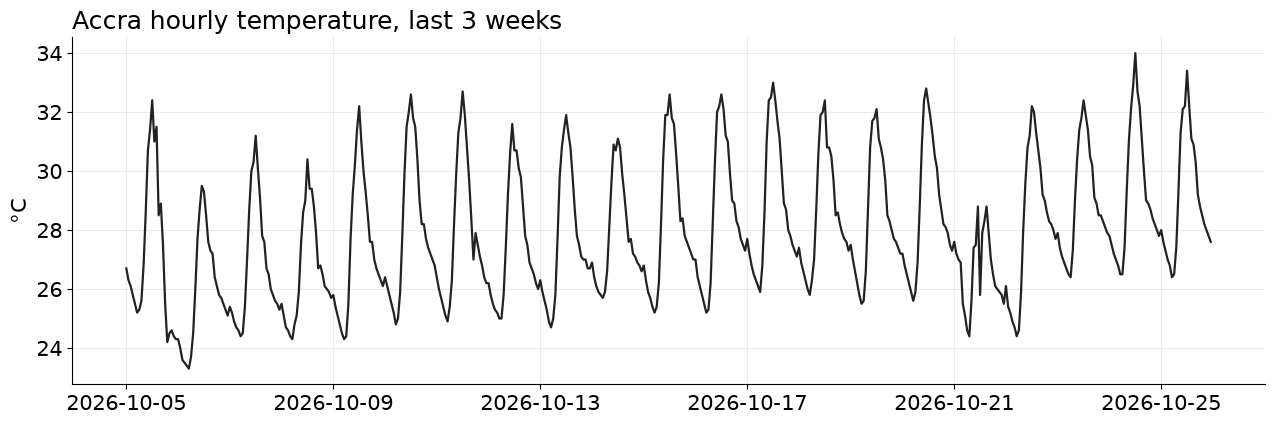

2,064 hours of data


In [2]:
DATA = "data/accra_hourly_2026.csv"
if not os.path.exists(DATA): DATA = "https://raw.githubusercontent.com/RichelCode/Youtube/main/forecasting-made-easy/01-can-ai-predict-tomorrow/" + DATA   # Colab: read it from GitHub
df = pd.read_csv(DATA)
df = df.rename(columns={"time": "ds", "temperature_2m": "y"})
df["ds"] = pd.to_datetime(df["ds"])
df["unique_id"] = "accra"
df = df[["unique_id", "ds", "y"]].dropna().sort_values("ds").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(13, 4.5))
last3 = df.tail(24 * 21)
ax.plot(last3.ds, last3.y, color="#222", lw=1.6)
ax.set(title="Accra hourly temperature, last 3 weeks", ylabel="°C")
plt.tight_layout(); plt.show()
print(f"{len(df):,} hours of data")

# A fair race: 56 days, one at a time

![Rolling windows: history the model may see, then the forecast](https://raw.githubusercontent.com/RichelCode/Youtube/main/forecasting-made-easy/01-can-ai-predict-tomorrow/figures/fig_rolling_origin.png)

**Use only the past, forecast the next day, slide forward one day, repeat.** 56 times.

- This is called **backtesting** (or rolling-origin evaluation)
- **In plain words:** judging a student on one quiz is unfair. One lucky day can fool you. 56 days cannot.
- In the code, `cross_validation` is just the library's name for this slide-forward test

In [3]:
from statsforecast import StatsForecast
from statsforecast.models import SeasonalNaive, AutoETS

recent = df.tail(CONTEXT + H * DAYS)
t0 = time.time()
race = StatsForecast(
    models=[SeasonalNaive(season_length=SEASON), AutoETS(season_length=SEASON)], freq="h"
).cross_validation(df=recent, h=H, step_size=H, n_windows=DAYS, level=[LEVEL])
print(f"Lazy forecast + AutoETS done on {DAYS} days in {time.time() - t0:.0f}s")

Lazy forecast + AutoETS done on 56 days in 20s


# Now the AI: Chronos-2, zero-shot

For each of the 56 days, we hand Chronos-2 **only the 4 weeks before that day** and ask for the next 24 hours.

- `history = df[df.ds <= cutoff]`: **only the past.** This one line keeps the race honest
- We ask for three lines: the **10th percentile** (low), the **median** (middle) and the **90th percentile** (high)
- Low to high = the **80% range**. The median is its main forecast

In [4]:
from chronos import Chronos2Pipeline
import transformers; transformers.logging.set_verbosity_error(); transformers.utils.logging.disable_progress_bar()

pipe = Chronos2Pipeline.from_pretrained("amazon/chronos-2", device_map="cpu")
lo_q, hi_q = 0.1, 0.9          # the 80% range

def col(frame, q):             # find the column for quantile q
    return next(c for c in frame.columns if str(c) == str(q))

t0 = time.time(); rows = []
for cutoff in sorted(race["cutoff"].unique()):
    history = df[df.ds <= cutoff].tail(CONTEXT)          # ONLY the past
    p = pipe.predict_df(history, prediction_length=H, quantile_levels=[lo_q, 0.5, hi_q],
                        id_column="unique_id", timestamp_column="ds", target="y")
    rows.append(pd.DataFrame({"unique_id": p["unique_id"], "ds": p["ds"], "cutoff": cutoff,
                              "Chronos2": p[col(p, 0.5)],
                              f"Chronos2-lo-{LEVEL}": p[col(p, lo_q)],
                              f"Chronos2-hi-{LEVEL}": p[col(p, hi_q)]}))
race = race.merge(pd.concat(rows, ignore_index=True), on=["unique_id", "ds", "cutoff"])
print(f"Chronos-2 forecast {DAYS} days in {time.time() - t0:.0f}s on a laptop CPU")

Chronos-2 forecast 56 days in 3s on a laptop CPU


# How do we score the race?

1. **Error:** for every hour, how far was the forecast from the real temperature?
   Ignore whether it was too high or too low, then average. This is the **average error in °C**
2. **Relative error:** a model's error **divided by** the lazy forecast's error
   - **Below 1** = better than the lazy forecast
   - **Above 1** = worse than the lazy forecast
3. **Days won:** on how many of the 56 days did the model beat the lazy forecast?

In [5]:
MODELS = ["SeasonalNaive", "AutoETS", "Chronos2"]
daily = pd.DataFrame({m: race.assign(e=(race.y - race[m]).abs()).groupby("cutoff")["e"].mean()
                      for m in MODELS})

table = pd.DataFrame({
    "avg error (°C)": daily.mean(),
    "relative error": daily.mean() / daily["SeasonalNaive"].mean(),
    "days beating lazy": [(daily[m] < daily["SeasonalNaive"]).sum() for m in MODELS],
}).round(3).sort_values("avg error (°C)")
table

,avg error (°C),relative error,days beating lazy
Chronos2,0.462,0.742,45
AutoETS,0.524,0.842,41
SeasonalNaive,0.622,1.000,0


# Who won?

- **Chronos-2: 0.74.** About **26% less error** than the lazy forecast, and it beat it on **45 of 56 days**
- **AutoETS: 0.84.** About **16% less error**. A classic model, still strong
- **Lazy forecast: 1.00.** The line everyone is measured against

**In plain words:** the AI won this race. Not magic, but a real improvement.
Everything to the left of the dashed line below is better than "same as yesterday".

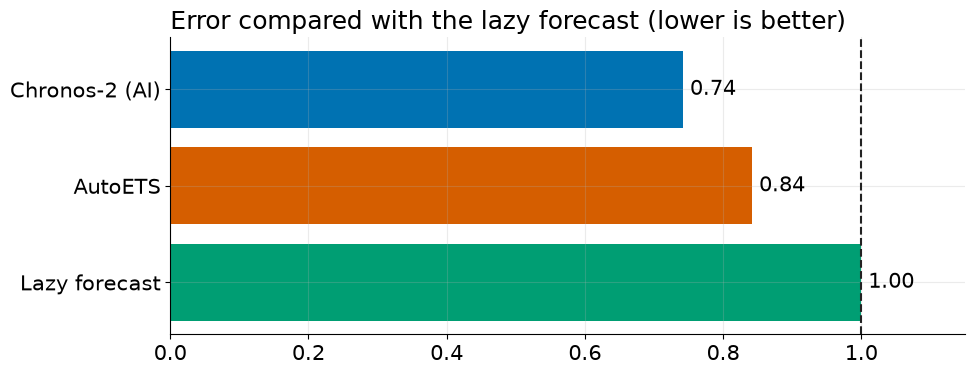

In [6]:
fig, ax = plt.subplots(figsize=(10, 4))
rel = table["relative error"].sort_values(ascending=False)
NAMES = {"SeasonalNaive": "Lazy forecast", "AutoETS": "AutoETS", "Chronos2": "Chronos-2 (AI)"}
ax.barh([NAMES[m] for m in rel.index], rel.values, color=[COLORS[m] for m in rel.index])
ax.axvline(1, color="#222", ls="--", lw=1.5)
for i, v in enumerate(rel.values):
    ax.text(v + 0.01, i, f"{v:.2f}", va="center", fontsize=15)
ax.set(title="Error compared with the lazy forecast (lower is better)", xlim=(0, 1.15))
plt.tight_layout(); plt.show()

# Was it just luck?

Maybe Chronos-2 just got the easy days? We check with the **bootstrap**.

- Imagine the 56 days as **56 cards in a hat**
- Draw 56 cards, **putting each one back** after you draw it (some days come up twice, some not at all)
- Work out the average difference between Chronos-2 and the lazy forecast
- Do that **5,000 times**

If Chronos-2 still wins in almost every reshuffle, the win is not down to a few lucky days.

In [7]:
rng = np.random.default_rng(42)
diff = (daily["Chronos2"] - daily["SeasonalNaive"]).values
boot = rng.choice(diff, (5000, len(diff))).mean(axis=1)
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"Chronos-2's average error is {-diff.mean():.2f} °C smaller than the lazy forecast's")
print(f"95% interval for the difference: [{lo:+.2f}, {hi:+.2f}] °C")
print("The whole interval is below zero: very unlikely to be luck" if hi < 0 else "The interval includes zero: it could be luck")

Chronos-2's average error is 0.16 °C smaller than the lazy forecast's
95% interval for the difference: [-0.23, -0.10] °C
The whole interval is below zero: very unlikely to be luck


# But can we trust its ranges?

An **80% range** should catch the real temperature **80% of the time**. Checking this is called checking **coverage**.

- Caught it **much less** than 80%: the model is **overconfident** (ranges too narrow)
- Caught it **much more** than 80%: the model is **too cautious** (ranges too wide to be useful)

**In plain words:** a weather app that says "27 to 30 °C, 80% sure" should be right about 8 days in 10.
Right only 6 days in 10? Do not plan your day around it.

In [8]:
for m in MODELS:
    inside = ((race.y >= race[f"{m}-lo-{LEVEL}"]) & (race.y <= race[f"{m}-hi-{LEVEL}"])).mean()
    width = (race[f"{m}-hi-{LEVEL}"] - race[f"{m}-lo-{LEVEL}"]).mean()
    print(f"{m:14s} caught the truth {inside:5.1%} of the time  (range about {width:.1f} °C wide)")

SeasonalNaive  caught the truth 82.7% of the time  (range about 2.1 °C wide)
AutoETS        caught the truth 79.8% of the time  (range about 1.5 °C wide)
Chronos2       caught the truth 74.7% of the time  (range about 1.4 °C wide)


# The twist

| Model | Caught the truth | Range width | Verdict |
|---|---|---|---|
| Chronos-2 | **74.7%** | about 1.4 °C | Best line, but **overconfident** |
| AutoETS | **79.8%** | about 1.5 °C | Almost exactly honest |
| Lazy forecast | **82.7%** | about 2.1 °C | Safe, but vague |

## The best guess and the most honest range are not the same thing.

# Three checks before you trust any AI forecast

1. **Beat the lazy forecast.** Always compare with "same as yesterday" (or "same week last year") first
2. **Test on many days, not one lucky week.** Backtest, using only the past each time
3. **Check the ranges, not just the line.** Coverage tells you if the model knows what it does not know

This was one city in one season. **Re-check on your own data.**

# Next episode

## Time Series Forecasting Explained Simply

Trend, seasonality and noise: the three things every forecast is made of, and how to split a series into them in Python.

The code from today is linked in the description.